# Bonus: xem tác dụng của camera fusion trên Waymo

Notebook này chạy lại pipeline với cùng segment, weights và seed của bài nộp. Nó lưu **4 ảnh BEV** cho frame 80, 83, 131, 134 và **1 ảnh FRONT** của frame 131 vào `student/bonus/`. Ảnh BEV có GT, track LiDAR, trạng thái fused trước/sau camera update, và một ô phóng to ở xe cải thiện nhiều nhất. Notebook đối chiếu số liệu mỗi frame với `grade_run_*.log` trước khi vẽ.

Chạy các cell theo thứ tự từ gốc repo với kernel dùng `.venv/bin/python`. Cell replay cần khoảng 2–4 phút trên CPU. Notebook không ghi vào `student/artifacts/` và không sửa code bài chấm.

Nếu VS Code/Jupyter yêu cầu `ipykernel`, chạy `uv pip install --python .venv/bin/python ipykernel` khi có mạng, rồi chọn interpreter `.venv/bin/python` làm kernel. Trong môi trường hiện tại, mã đã được kiểm tra bằng chính Python của `.venv`.

In [5]:
from pathlib import Path
import json
import os
import sys
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "student/config/paths.yaml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Mở notebook từ thư mục repo hoặc student/bonus")
sys.path.insert(0, str(ROOT / "platform"))
sys.path.insert(0, str(ROOT / "platform/third_party/waymo_reader"))

from simple_waymo_open_dataset_reader import WaymoDataFileReader, dataset_pb2, label_pb2
from simple_waymo_open_dataset_reader import utils as waymo_utils
from fusion_lab import tracking_params
from fusion_lab.evaluation import tracking_counts, valid_ground_truth, _partial_assignment
from fusion_lab.lidar_pcl import pcl_from_range_image
from fusion_lab.scripts.run_lab import _front_observations, _lidar_observations
from fusion_lab.tracking.filter import Filter
from fusion_lab.tracking.manager import TrackManager
from fusion_lab.tracking.sensors import Sensor
from fusion_lab.workspace_loader import load_workspace

FRAMES = (80, 83, 131, 134)
SEED = 0
OUT = ROOT / "student/bonus"
OUT.mkdir(parents=True, exist_ok=True)
SEGMENT = ROOT / "data/Waymo/training_segment-1005081002024129653_5313_150_5333_150_with_camera_labels.tfrecord"
WEIGHTS = ROOT / "data/weights/pretrained_fpn-resnet/fpn_resnet_18_epoch_300.pth"
for path in (SEGMENT, WEIGHTS):
    if not path.is_file():
        raise FileNotFoundError(path)

def read_log(mode):
    path = ROOT / f"student/artifacts/grade_run_{mode}.log"
    return {row["frame"]: row for row in map(json.loads, path.read_text().splitlines())}

REFERENCE = {mode: read_log(mode) for mode in ("lidar", "fused")}
print("Repo:", ROOT)
print("Ảnh sẽ lưu tại:", OUT)


Repo: /home/kah/track4/K4-L2L3-DAY23-HoangTrungKhai-2A202602947-SensorFusion
Ảnh sẽ lưu tại: /home/kah/track4/K4-L2L3-DAY23-HoangTrungKhai-2A202602947-SensorFusion/student/bonus


## Top 5 frame đáng xem

Xếp hạng theo mức giảm tổng sai số bình phương của cả frame; chỉ xét frame mà hai mode đều ghép được GT.

In [ ]:
# Top 5 frame có tổng sai số bình phương giảm nhiều nhất sau fusion.
ranked_frames = []
for frame_no in sorted(set(REFERENCE["lidar"]) & set(REFERENCE["fused"])):
    lidar_row = REFERENCE["lidar"][frame_no]
    fused_row = REFERENCE["fused"][frame_no]
    if lidar_row["matches"] and fused_row["matches"]:
        improvement = lidar_row["sum_sq_err"] - fused_row["sum_sq_err"]
        ranked_frames.append((improvement, frame_no, lidar_row, fused_row))

top5 = sorted(ranked_frames, reverse=True)[:5]
for rank, (improvement, frame_no, lidar_row, fused_row) in enumerate(top5, 1):
    print(f"{rank}. frame={frame_no:3d}, matches={lidar_row['matches']}, "
          f"LiDAR SSE={lidar_row['sum_sq_err']:.4f}, "
          f"fused SSE={fused_row['sum_sq_err']:.4f}, "
          f"giảm={improvement:.4f} m²")
# Sửa FRAMES trong cell cấu hình nếu muốn vẽ những frame khác.


## Chạy lại tracker đến frame 134

Detector chỉ chạy một lần mỗi frame; hai `TrackManager` riêng cho LiDAR và fused cùng nhận detection. Trạng thái fused được chụp trước và sau lượt camera. `assert` sẽ báo lỗi nếu số liệu không khớp log gốc.

In [6]:
def snapshot(tracks):
    return [{
        "id": int(t.id),
        "state": t.state,
        "score": float(t.score),
        "xyz": np.asarray(t.x, dtype=float).reshape(-1)[:3].tolist(),
    } for t in tracks]

ws = load_workspace()
bev = ws["bev_mapping"]
det = ws["detection_pipeline"]
cam = ws["camera_fusion"]
config = det.load_fpn_resnet_config(str(WEIGHTS))
model = det.create_fpn_model(config, str(WEIGHTS))
filter_obj = Filter(ws["kalman"])
managers = {mode: TrackManager(ws["track_management"]) for mode in ("lidar", "fused")}
rng = np.random.default_rng(SEED)
lidar_sensor = None
camera_sensor = None
captured = {}
front_jpeg = {}

for frame_no, frame in enumerate(WaymoDataFileReader(str(SEGMENT))):
    if frame_no > max(FRAMES):
        break
    if lidar_sensor is None:
        calib = waymo_utils.get(frame.context.laser_calibrations, dataset_pb2.LaserName.TOP)
        lidar_sensor = Sensor("lidar", calib, cam)
        camera_calib = waymo_utils.get(frame.context.camera_calibrations, dataset_pb2.CameraName.FRONT)
        camera_sensor = Sensor("camera", camera_calib, cam)

    points = pcl_from_range_image(frame, dataset_pb2.LaserName.TOP)
    tensor = torch.from_numpy(bev.bev_maps_from_pcl(points, config)).unsqueeze(0).float()
    detections = det.detect_objects_from_bev(tensor, model, config)
    labels = valid_ground_truth(frame.laser_labels, config, label_pb2.Label.Type.TYPE_VEHICLE)
    observations = _lidar_observations(frame_no, detections, lidar_sensor, config)

    for manager in managers.values():
        for track in manager.track_list:
            filter_obj.predict(track)
            track.set_t(frame_no * tracking_params.dt)
        ws["association"].associate_and_update(manager, observations, filter_obj, lidar_sensor)

    before_camera = snapshot(managers["fused"].track_list)
    camera_observations = _front_observations(
        frame, frame_no, camera_sensor, rng,
        dataset_pb2.CameraName.FRONT, label_pb2.Label.Type.TYPE_VEHICLE,
    )
    if camera_observations is not None:
        ws["association"].associate_and_update(
            managers["fused"], camera_observations, filter_obj, camera_sensor
        )

    if frame_no not in FRAMES:
        continue

    counts = {mode: tracking_counts(manager.track_list, labels)
              for mode, manager in managers.items()}
    for mode in ("lidar", "fused"):
        original = REFERENCE[mode][frame_no]
        actual = counts[mode]
        for key in ("matches", "ghosts", "misses", "confirmed"):
            assert actual[key] == original[key], (frame_no, mode, key, actual[key], original[key])
        assert np.isclose(actual["sum_sq_err"], original["sum_sq_err"], atol=1e-7), (frame_no, mode)

    front_group = next((g for g in frame.camera_labels
                        if g.name == dataset_pb2.CameraName.FRONT), None)
    boxes = [] if front_group is None else [{
        "id": label.id,
        "cx": float(label.box.center_x), "cy": float(label.box.center_y),
        "width": float(label.box.length), "height": float(label.box.width),
    } for label in front_group.labels if label.type == label_pb2.Label.Type.TYPE_VEHICLE]
    if frame_no == 131:
        front = next(im for im in frame.images if im.name == dataset_pb2.CameraName.FRONT)
        front_jpeg[frame_no] = bytes(front.image)

    captured[frame_no] = {
        "frame": frame_no,
        "gt": [{"id": label.id, "xyz": [float(label.box.center_x),
                                          float(label.box.center_y),
                                          float(label.box.center_z)]} for label in labels],
        "lidar": snapshot(managers["lidar"].track_list),
        "fused_before_camera": before_camera,
        "fused": snapshot(managers["fused"].track_list),
        "counts": counts,
        "front_boxes": boxes,
        "pcl_xy": points[::50, :2].astype(float).tolist(),
    }
    print(f"Frame {frame_no}: LiDAR {counts['lidar']['matches']} matches, "
          f"SSE={counts['lidar']['sum_sq_err']:.4f}; "
          f"fused {counts['fused']['matches']} matches, "
          f"SSE={counts['fused']['sum_sq_err']:.4f}; khớp log")

assert set(captured) == set(FRAMES)
(OUT / "track_snapshots.json").write_text(json.dumps(captured, indent=2))
print("Đã lưu", OUT / "track_snapshots.json")


Frame 80: LiDAR 2 matches, SSE=0.0909; fused 2 matches, SSE=0.0325; khớp log
Frame 83: LiDAR 2 matches, SSE=0.0959; fused 2 matches, SSE=0.0357; khớp log
Frame 131: LiDAR 3 matches, SSE=0.1230; fused 3 matches, SSE=0.0581; khớp log
Frame 134: LiDAR 3 matches, SSE=0.1164; fused 3 matches, SSE=0.0538; khớp log
Đã lưu /home/kah/track4/K4-L2L3-DAY23-HoangTrungKhai-2A202602947-SensorFusion/student/bonus/track_snapshots.json


## Vẽ BEV: toàn cảnh và xe cải thiện nhiều nhất

Xanh: track chỉ LiDAR; cam: trạng thái fused sau LiDAR nhưng trước camera; đỏ: fused sau camera; sao đen: GT. Mũi tên nối trạng thái trước/sau camera của **cùng track ID**. Ô bên phải phóng to xe có mức giảm sai số bình phương lớn nhất ở frame đó.

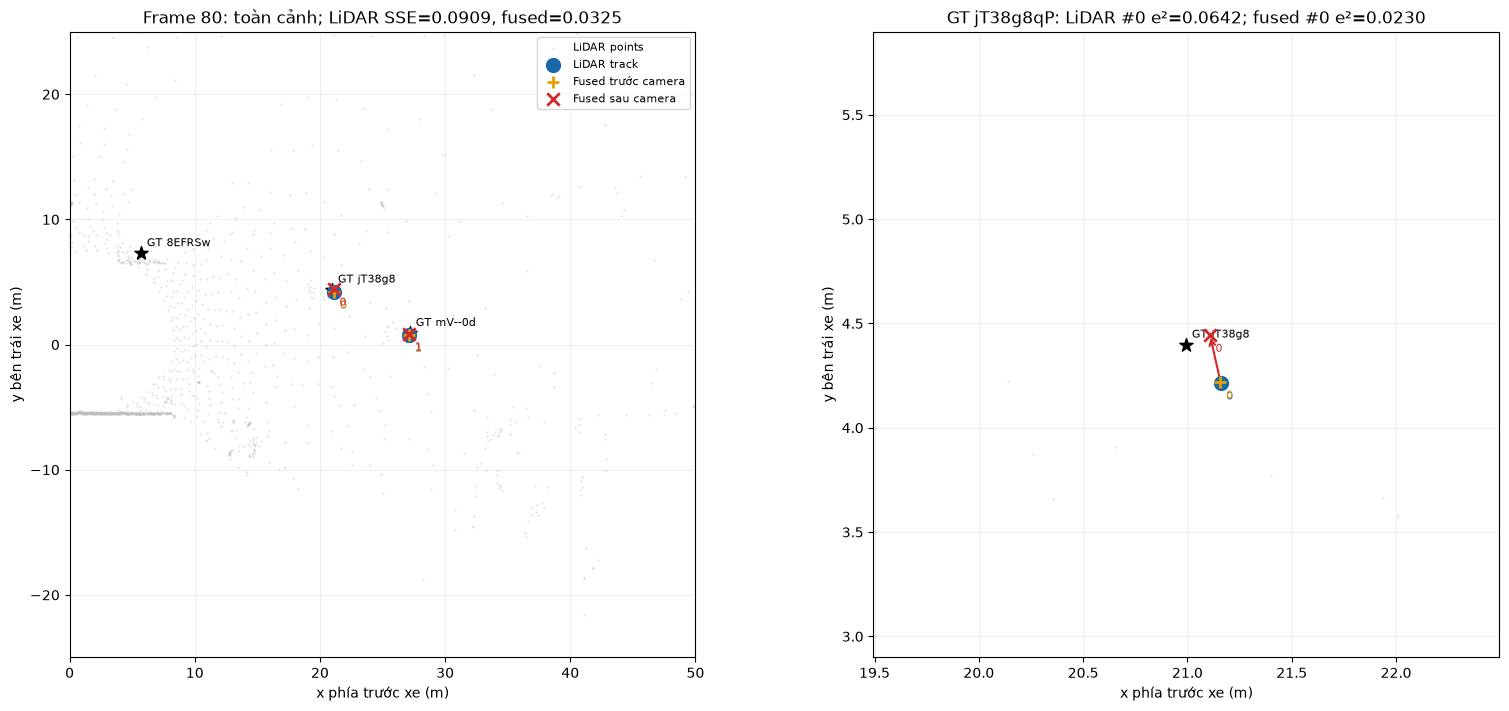

Đã lưu /home/kah/track4/K4-L2L3-DAY23-HoangTrungKhai-2A202602947-SensorFusion/student/bonus/frame_080_bev.png


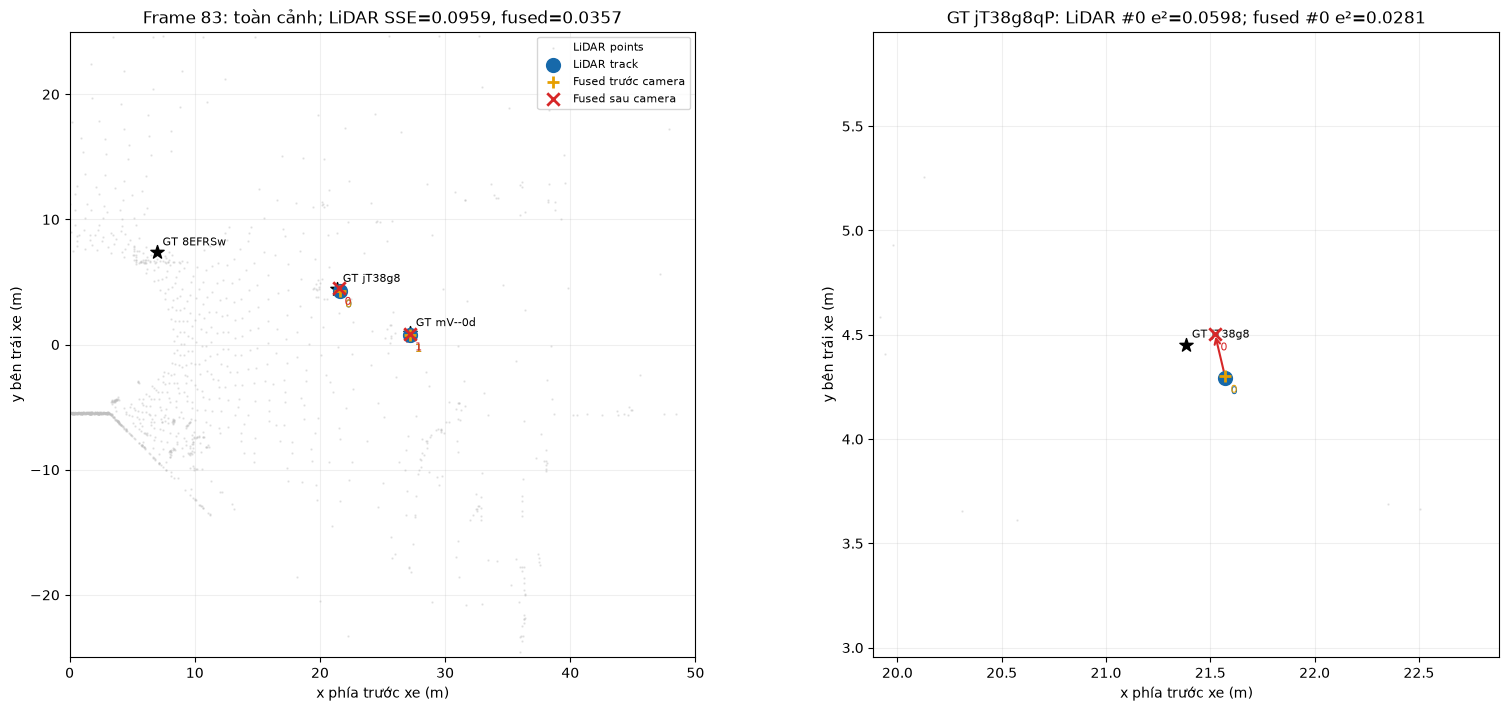

Đã lưu /home/kah/track4/K4-L2L3-DAY23-HoangTrungKhai-2A202602947-SensorFusion/student/bonus/frame_083_bev.png


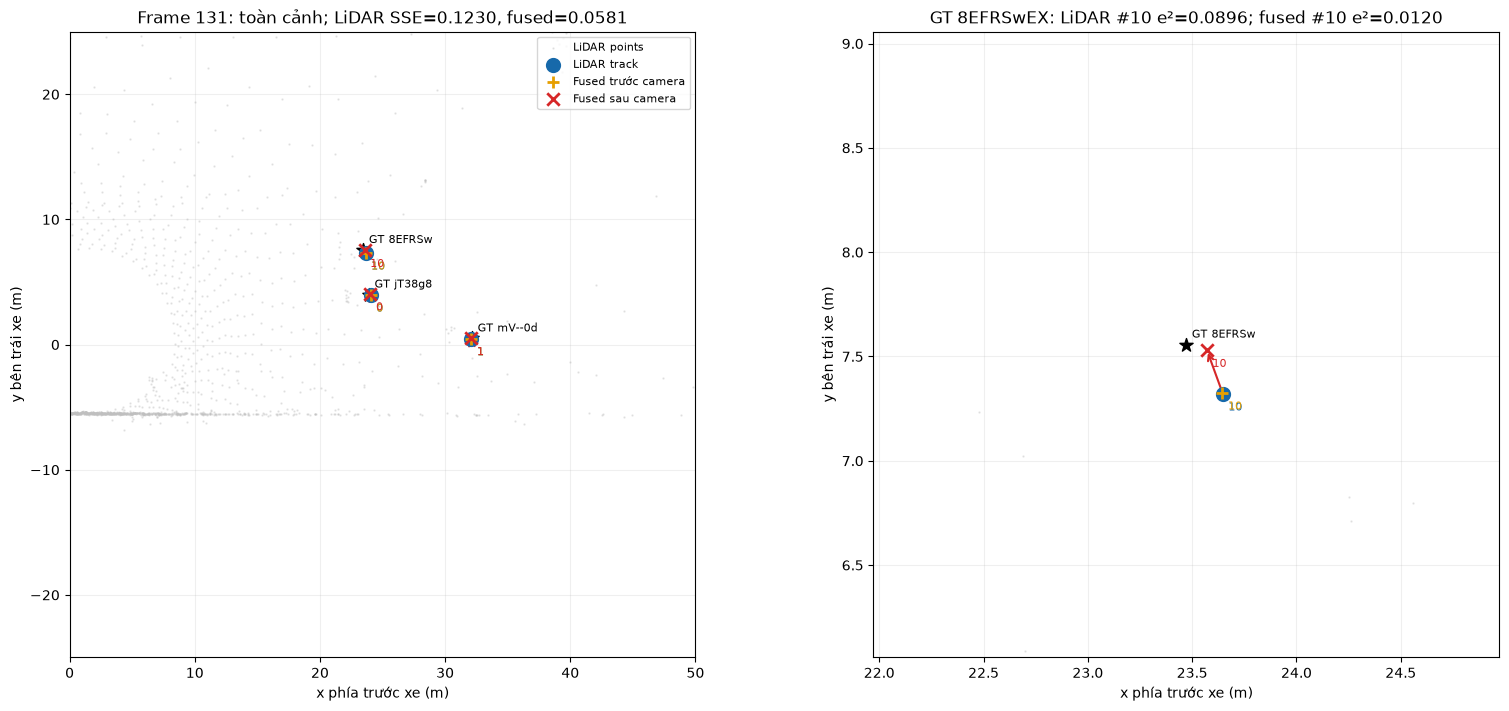

Đã lưu /home/kah/track4/K4-L2L3-DAY23-HoangTrungKhai-2A202602947-SensorFusion/student/bonus/frame_131_bev.png


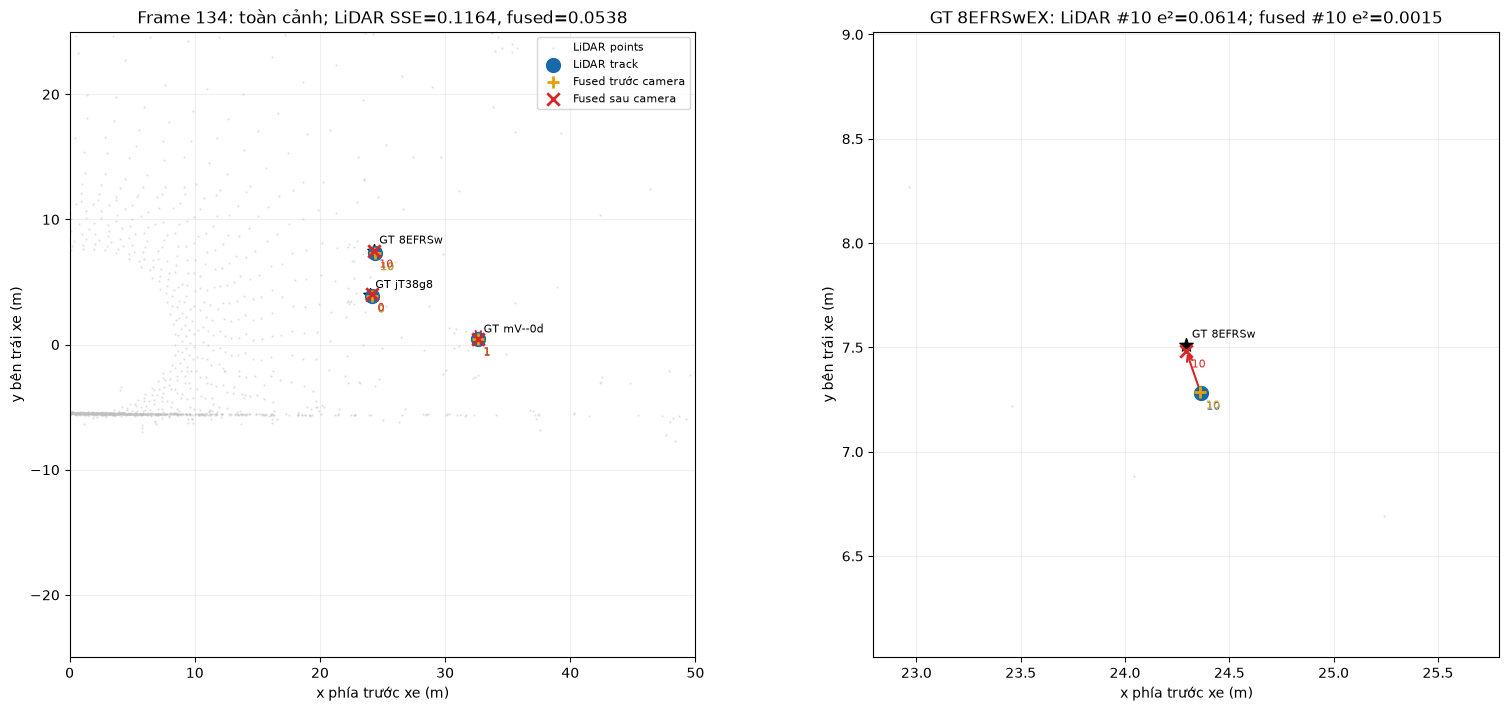

Đã lưu /home/kah/track4/K4-L2L3-DAY23-HoangTrungKhai-2A202602947-SensorFusion/student/bonus/frame_134_bev.png


In [7]:
def confirmed(data, key):
    return [t for t in data[key] if t["state"] == "confirmed"]

def matched_by_gt(tracks, gt):
    if not tracks or not gt:
        return {}
    track_xyz = np.asarray([t["xyz"] for t in tracks])
    gt_xyz = np.asarray([g["xyz"] for g in gt])
    distance_xy = np.linalg.norm(track_xyz[:, None, :2] - gt_xyz[None, :, :2], axis=2)
    pairs = _partial_assignment(distance_xy, np.isfinite(distance_xy) & (distance_xy <= 2.0))
    return {j: (tracks[i], float(np.sum((track_xyz[i] - gt_xyz[j]) ** 2)))
            for i, j in pairs}

def draw_scene(ax, data, zoom=None):
    cloud = np.asarray(data["pcl_xy"])
    if cloud.size:
        ax.scatter(cloud[:, 0], cloud[:, 1], s=0.5, c="0.75", alpha=0.35, label="LiDAR points")
    for g in data["gt"]:
        x, y = g["xyz"][:2]
        ax.scatter(x, y, marker="*", s=100, c="black", zorder=5)
        ax.annotate("GT " + g["id"][:6], (x, y), xytext=(4, 5),
                    textcoords="offset points", fontsize=8)
    styles = [("lidar", "#1769aa", "o", "LiDAR track"),
              ("fused_before_camera", "#e69f00", "+", "Fused trước camera"),
              ("fused", "#d62728", "x", "Fused sau camera")]
    for key, color, marker, label in styles:
        tracks = confirmed(data, key)
        if tracks:
            xy = np.asarray([t["xyz"][:2] for t in tracks])
            ax.scatter(xy[:, 0], xy[:, 1], marker=marker, s=80,
                       linewidths=2, c=color, label=label, zorder=6)
            for t in tracks:
                ax.annotate(str(t["id"]), t["xyz"][:2], xytext=(4, -12),
                            textcoords="offset points", color=color, fontsize=8)
    before = {t["id"]: t for t in confirmed(data, "fused_before_camera")}
    for after in confirmed(data, "fused"):
        old = before.get(after["id"])
        if old is not None:
            ax.annotate("", xy=after["xyz"][:2], xytext=old["xyz"][:2],
                        arrowprops={"arrowstyle": "->", "color": "#d62728", "lw": 1.5})
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x phía trước xe (m)")
    ax.set_ylabel("y bên trái xe (m)")
    ax.grid(alpha=0.2)
    if zoom is None:
        ax.set_xlim(0, 50)
        ax.set_ylim(-25, 25)
    else:
        ax.set_xlim(zoom[0] - 1.5, zoom[0] + 1.5)
        ax.set_ylim(zoom[1] - 1.5, zoom[1] + 1.5)

for frame_no in FRAMES:
    data = captured[frame_no]
    lidar_pairs = matched_by_gt(confirmed(data, "lidar"), data["gt"])
    fused_pairs = matched_by_gt(confirmed(data, "fused"), data["gt"])
    common = set(lidar_pairs) & set(fused_pairs)
    best = max(common, key=lambda j: lidar_pairs[j][1] - fused_pairs[j][1]) if common else None
    zoom = data["gt"][best]["xyz"][:2] if best is not None else [25, 0]
    lc, fc = data["counts"]["lidar"], data["counts"]["fused"]
    fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
    draw_scene(axes[0], data)
    axes[0].set_title(f"Frame {frame_no}: toàn cảnh; LiDAR SSE={lc['sum_sq_err']:.4f}, fused={fc['sum_sq_err']:.4f}")
    draw_scene(axes[1], data, zoom=zoom)
    if best is not None:
        lid_track, lid_error = lidar_pairs[best]
        fus_track, fus_error = fused_pairs[best]
        axes[1].set_title(f"GT {data['gt'][best]['id'][:8]}: LiDAR #{lid_track['id']} e²={lid_error:.4f}; "
                          f"fused #{fus_track['id']} e²={fus_error:.4f}")
    else:
        axes[1].set_title("Không có GT ghép chung ở hai mode")
    axes[0].legend(loc="upper right", fontsize=8)
    path = OUT / f"frame_{frame_no:03d}_bev.png"
    fig.savefig(path, dpi=150)
    plt.show()
    plt.close(fig)
    print("Đã lưu", path)


## Ảnh FRONT frame 131

Hộp xanh là nhãn camera GT, không phải camera detector hay track. Dùng ảnh này để nhận diện cảnh; ảnh BEV phía trên là bằng chứng về vị trí track.

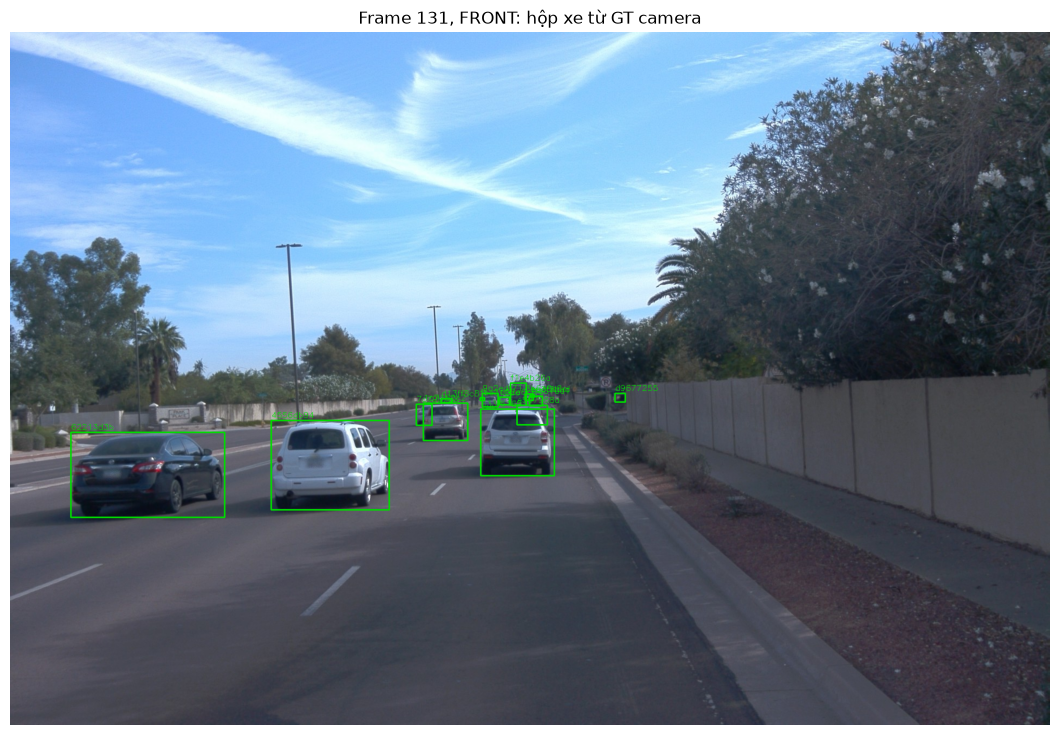

Đã lưu /home/kah/track4/K4-L2L3-DAY23-HoangTrungKhai-2A202602947-SensorFusion/student/bonus/frame_131_front.jpg


In [8]:
frame_no = 131
image = cv2.imdecode(np.frombuffer(front_jpeg[frame_no], dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError("Không đọc được ảnh FRONT")
for box in captured[frame_no]["front_boxes"]:
    x1 = int(box["cx"] - box["width"] / 2)
    y1 = int(box["cy"] - box["height"] / 2)
    x2 = int(box["cx"] + box["width"] / 2)
    y2 = int(box["cy"] + box["height"] / 2)
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 220, 0), 2)
    cv2.putText(image, box["id"][:8], (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 220, 0), 1)
path = OUT / "frame_131_front.jpg"
cv2.imwrite(str(path), image)
plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Frame 131, FRONT: hộp xe từ GT camera")
plt.show()
print("Đã lưu", path)


## Ghi báo cáo bonus

Xem `frame_131_bev.png` và các frame khác, chọn track ID có mũi tên camera rõ ràng và ghi mức thay đổi sai số từ tiêu đề ô phóng to. Dẫn tên 2–5 ảnh trong `student/SUBMISSION.md`. `track_snapshots.json` là dữ liệu trung gian để kiểm tra lại ID/toạ độ. Không dùng ảnh FRONT như bằng chứng của một camera detector: các hộp xanh đến từ nhãn GT.

Notebook này phục vụ mục **trực quan hoá +3**. Mục calibration và CVAT cần thí nghiệm riêng.